# Week 6 - Bivariate Analysis, part 2

# 1. Lesson: no lesson this week

# 2. Weekly graph question

Suppose you wanted to show the nitrate and phosphate level in a water sample.  What are the advantages and disadvantages of showing this as an area plot, as opposed to two separate line graphs?  How would you adjust the graphs shown to improve the presentation?

In [2]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

sns.set_style("whitegrid")

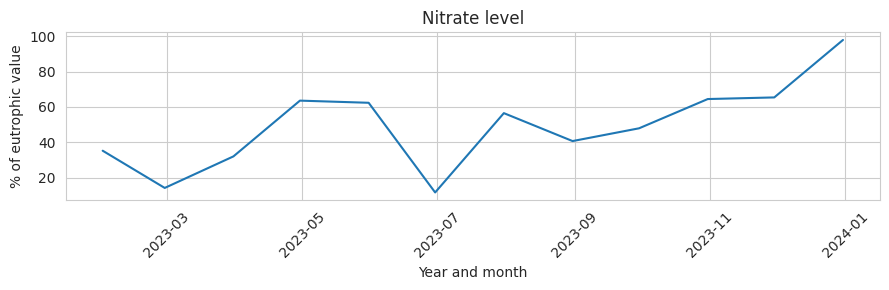

In [8]:
numdates = 12
np.random.seed(0)
time_series = 100 * (np.random.normal(size=numdates) / 5 + np.arange(numdates) / 16)
datearray = pd.date_range(start="2023-01-31", periods=numdates, freq="ME")

plt.figure(figsize=(9, 3))
sns.lineplot(x=datearray, y=time_series)
plt.title("Nitrate level")
plt.xlabel("Year and month")
plt.ylabel("% of eutrophic value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

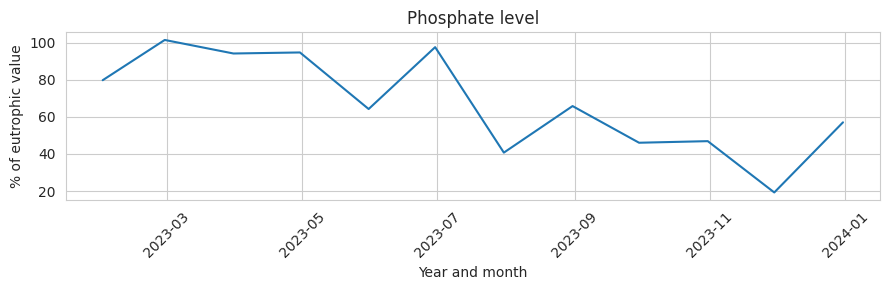

In [7]:
np.random.seed(1)
time_series_2 = 100 * (1 - (np.random.normal(size=numdates) / 8 + np.arange(numdates) / 16))

plt.figure(figsize=(9, 3))
sns.lineplot(x=datearray, y=time_series_2)
plt.title("Phosphate level")
plt.xlabel("Year and month")
plt.ylabel("% of eutrophic value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

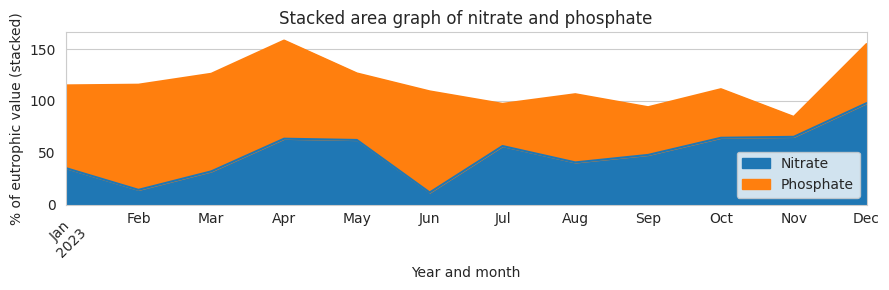

In [6]:
water_df = pd.DataFrame({"Nitrate": time_series, "Phosphate": time_series_2}, index=datearray)
water_df.plot.area(figsize=(9, 3))
plt.title("Stacked area graph of nitrate and phosphate")
plt.xlabel("Year and month")
plt.ylabel("% of eutrophic value (stacked)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

An area plot is good for showing how the two measurements change over time. It can also make the total look important. However, a stacked area plot adds nitrate and phosphate together, which can be confusing because these are two different measurements with their own limits. It also makes the phosphate trend harder to compare because its baseline moves.
Two separate line graphs make it easier to follow each measurement. The disadvantage is that we have to look back and forth between the graphs to compare them.
I would use one line graph with both lines because both values are percentages of their own eutrophic limits. I would add a clear title, simple labels, different colors, and a line at 100% to show the threshold. I would remove extra clutter and use the same time axis.

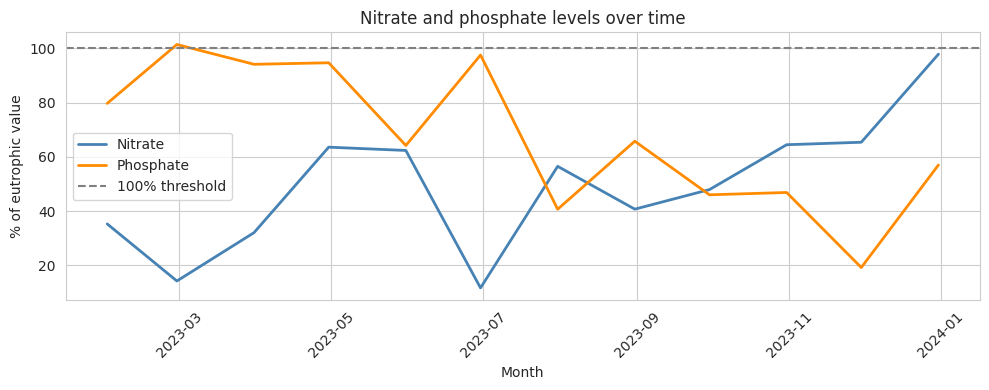

In [9]:
plt.figure(figsize=(10, 4))
plt.plot(datearray, time_series, color="steelblue", label="Nitrate", linewidth=2)
plt.plot(datearray, time_series_2, color="darkorange", label="Phosphate", linewidth=2)
plt.axhline(y=100, color="gray", linestyle="--", label="100% threshold")
plt.title("Nitrate and phosphate levels over time")
plt.xlabel("Month")
plt.ylabel("% of eutrophic value")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

### Here are some types of analysis you can do:

- Find correlations between pairs of variables.

- Draw scatterplots, especially when the correlation is large.

- Draw pairplots.

- Draw line graphs and/or area graphs when there is date or time data together with numerical data.

### Conclusions:

- Explain what conclusions you would draw from this analysis: are the data what you expect?  Are the data likely to be usable?  If the data are not useable, find some new data!

- Do you see any outliers?  (Data points that are far from the rest of the data).

- Are any data items highly correlated with each other, suggesting that they are redundant?

- For the line plots, do you see a trend or pattern over time?  Does this suggest that the data are changing over time (drifting) in such a way as to invalidate comparisons?

- Can you think of any confounding variables?  (Third variables that could explain any correlations between other variables.  These third variables may or may not be reported in the dataset.)

In [14]:
ecuador_long = pd.read_csv("ecuador_macro_long.csv")
print("Rows and columns:", ecuador_long.shape)
print("Years:", ecuador_long["year"].min(), "to", ecuador_long["year"].max())
print("Indicators:", ecuador_long["indicator_name"].nunique())
display(ecuador_long.head())

Rows and columns: (275, 4)
Years: 1995 to 2025
Indicators: 9


,year,indicator,indicator_name,value
0,1995,FP.CPI.TOTL,cpi_index_2010_100,6.919400e+00
1,1995,FP.CPI.TOTL.ZG,inflation_cpi_annual_pct,2.293410e+01
2,1995,NE.CON.PRVT.KD.ZG,household_consumption_growth_pct,3.984300e+00
3,1995,NY.GDP.MKTP.CD,gdp_current_usd,2.443288e+10
4,1995,NY.GDP.MKTP.KD.ZG,gdp_growth_annual_pct,2.252500e+00


In [15]:
ecuador = ecuador_long.pivot(index="year", columns="indicator_name", values="value")

print("Dataset after pivoting:", ecuador.shape)
print("Missing values by indicator:")
print(ecuador.isna().sum())
display(ecuador.head())

Dataset after pivoting: (31, 9)
Missing values by indicator:
indicator_name
cpi_index_2010_100                  0
fx_rate_lcus_per_usd                0
gdp_current_usd                     0
gdp_growth_annual_pct               0
household_consumption_growth_pct    0
inflation_cpi_annual_pct            0
oil_rents_pct_gdp                   4
population                          0
unemployment_pct                    0
dtype: int64


indicator_name,cpi_index_2010_100,fx_rate_lcus_per_usd,gdp_current_usd,gdp_growth_annual_pct,household_consumption_growth_pct,inflation_cpi_annual_pct,oil_rents_pct_gdp,population,unemployment_pct
year,,,,,,,,,
1995,6.9194,2564.4942,2.443288e+10,2.2525,3.9843,22.9341,6.4537,11590514.0,4.408
1996,8.6086,3189.4742,2.522639e+10,1.7317,1.2647,24.4115,7.7879,11810950.0,4.422
1997,11.2478,3998.2667,2.816205e+10,4.3279,5.9587,30.6576,6.1722,12031127.0,4.424
1998,15.3080,5446.5729,2.798190e+10,3.2665,6.8838,36.0984,3.2121,12251184.0,4.389
1999,23.3052,11786.8017,1.964527e+10,-4.7394,-12.1964,52.2420,7.8633,12470795.0,4.656


Correlations

indicator_name                    gdp_growth_annual_pct  \
indicator_name                                            
gdp_growth_annual_pct                              1.00   
household_consumption_growth_pct                   0.73   
inflation_cpi_annual_pct                          -0.18   
unemployment_pct                                  -0.40   
oil_rents_pct_gdp                                  0.45   

indicator_name                    household_consumption_growth_pct  \
indicator_name                                                       
gdp_growth_annual_pct                                         0.73   
household_consumption_growth_pct                              1.00   
inflation_cpi_annual_pct                                     -0.28   
unemployment_pct                                             -0.37   
oil_rents_pct_gdp                                             0.22   

indicator_name                    inflation_cpi_annual_pct  unemployment_pct  \
indicator_name 

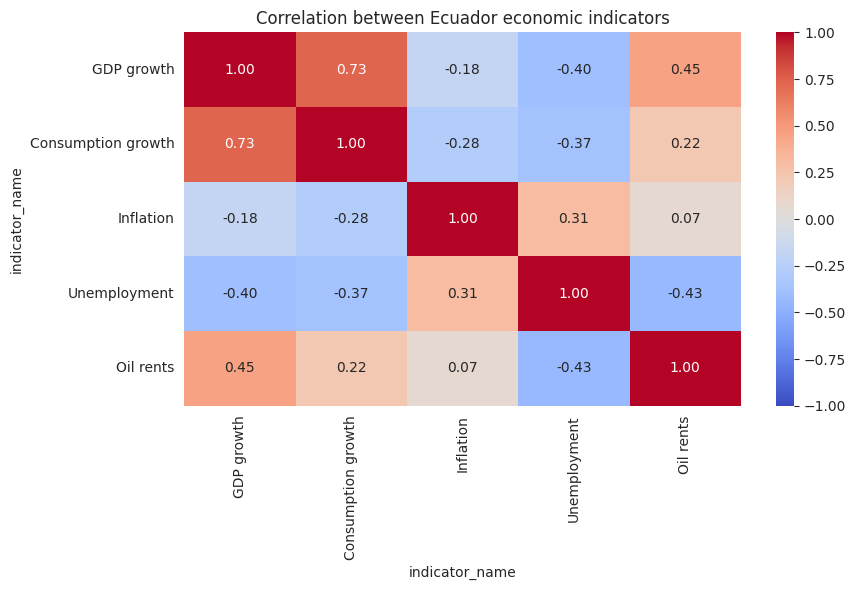

In [16]:
columns = [
    "gdp_growth_annual_pct",
    "household_consumption_growth_pct",
    "inflation_cpi_annual_pct",
    "unemployment_pct",
    "oil_rents_pct_gdp"
]

correlations = ecuador[columns].corr()
print(correlations.round(2))

plt.figure(figsize=(9, 6))

short_names = {
    "gdp_growth_annual_pct": "GDP growth",
    "household_consumption_growth_pct": "Consumption growth",
    "inflation_cpi_annual_pct": "Inflation",
    "unemployment_pct": "Unemployment",
    "oil_rents_pct_gdp": "Oil rents"
}
simple_corr = correlations.rename(index=short_names, columns=short_names)
sns.heatmap(simple_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation between Ecuador economic indicators")
plt.tight_layout()
plt.show()

In [17]:
print("GDP growth and consumption growth:", round(ecuador["gdp_growth_annual_pct"].corr(ecuador["household_consumption_growth_pct"]), 2))
print("GDP growth and unemployment:", round(ecuador["gdp_growth_annual_pct"].corr(ecuador["unemployment_pct"]), 2))
print("GDP growth and oil rents:", round(ecuador["gdp_growth_annual_pct"].corr(ecuador["oil_rents_pct_gdp"]), 2))
print("Population and nominal GDP:", round(ecuador["population"].corr(ecuador["gdp_current_usd"]), 2))

GDP growth and consumption growth: 0.73
GDP growth and unemployment: -0.4
GDP growth and oil rents: 0.45
Population and nominal GDP: 0.97


GDP growth and household consumption growth have a positive correlation of about 0.73, which is fairly strong. When the economy grows, household spending often grows too. GDP growth and unemployment have a negative correlation of about -0.40. GDP growth and oil rents have a positive correlation of about 0.45 (using the years with available oil-rent data).
Population and GDP in current U.S. dollars have an even higher correlation (about 0.97), but this does not mean they measure the same thing. Both increase over time, so the shared trend can make their correlation look especially strong. Correlation does not prove that one variable causes another.

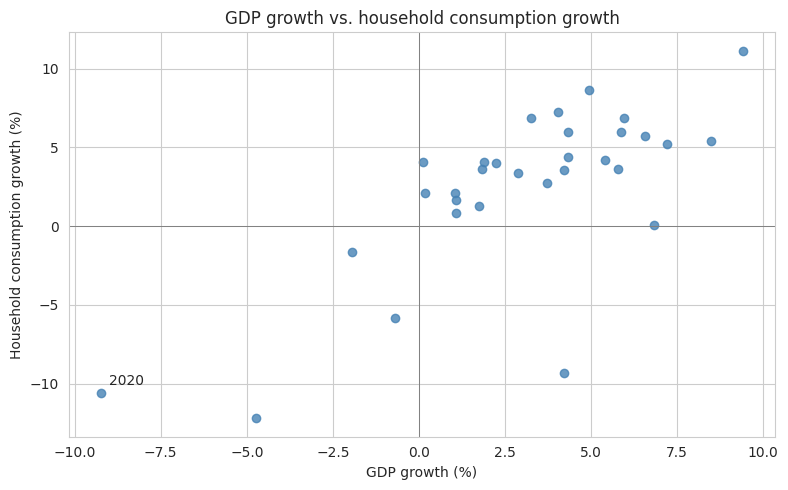

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(ecuador["gdp_growth_annual_pct"],
            ecuador["household_consumption_growth_pct"],
            color="steelblue", alpha=0.8)

plt.annotate("2020", (ecuador.loc[2020, "gdp_growth_annual_pct"],
                       ecuador.loc[2020, "household_consumption_growth_pct"]),
             xytext=(6, 6), textcoords="offset points")
plt.title("GDP growth vs. household consumption growth")
plt.xlabel("GDP growth (%)")
plt.ylabel("Household consumption growth (%)")
plt.axhline(0, color="gray", linewidth=0.7)
plt.axvline(0, color="gray", linewidth=0.7)
plt.tight_layout()
plt.show()

Most points show that higher GDP growth tends to come with higher household consumption growth. The points are not exactly on a straight line, so other factors probably matter. The 2020 point is unusual because both growth rates were very negative.

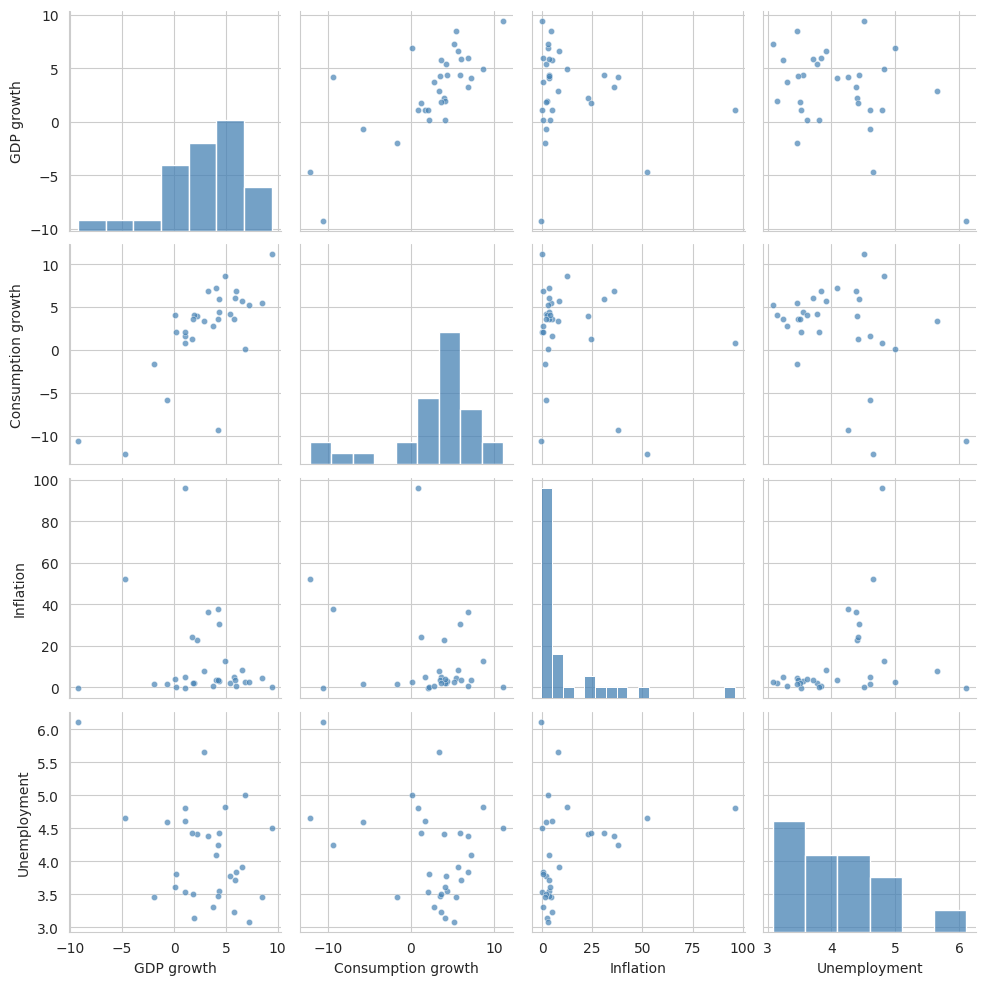

In [19]:
pair_columns = [
    "gdp_growth_annual_pct",
    "household_consumption_growth_pct",
    "inflation_cpi_annual_pct",
    "unemployment_pct"
]

pair_data = ecuador[pair_columns].rename(columns={
    "gdp_growth_annual_pct": "GDP growth",
    "household_consumption_growth_pct": "Consumption growth",
    "inflation_cpi_annual_pct": "Inflation",
    "unemployment_pct": "Unemployment"
})
sns.pairplot(pair_data, diag_kind="hist",
             plot_kws={"color": "steelblue", "alpha": 0.7, "s": 20},
             diag_kws={"color": "steelblue"})
plt.show()

The clearest pattern is between GDP growth and household consumption growth. Inflation is different: it has some very high values, which can make other patterns harder to see. The pairplot helps me identify which variables I should study more closely.

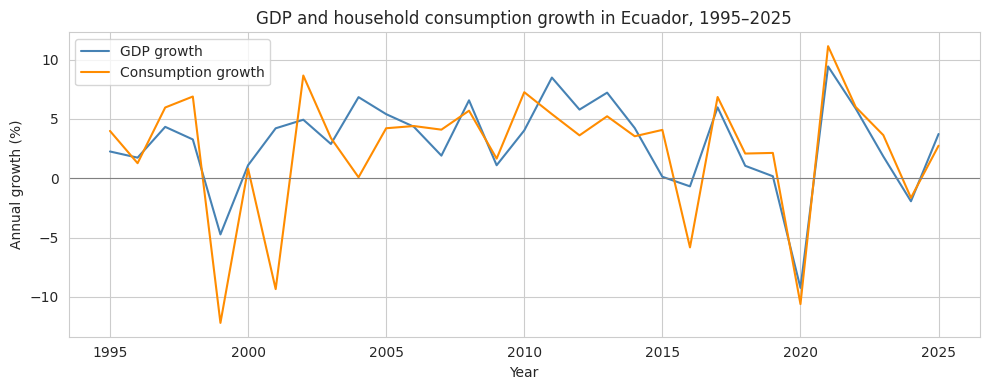

In [20]:
plt.figure(figsize=(10, 4))
plt.plot(ecuador.index, ecuador["gdp_growth_annual_pct"], label="GDP growth", color="steelblue")
plt.plot(ecuador.index, ecuador["household_consumption_growth_pct"], label="Consumption growth", color="darkorange")
plt.axhline(0, color="gray", linewidth=0.8)
plt.title("GDP and household consumption growth in Ecuador, 1995–2025")
plt.xlabel("Year")
plt.ylabel("Annual growth (%)")
plt.legend()
plt.tight_layout()
plt.show()

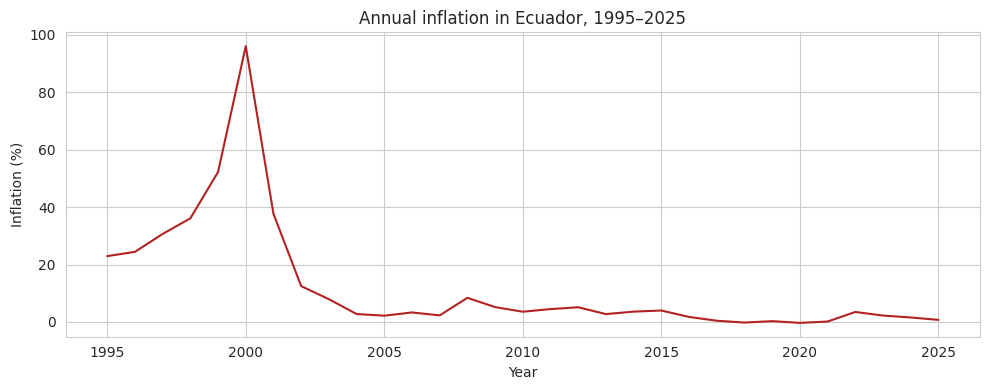

In [21]:
plt.figure(figsize=(10, 4))
plt.plot(ecuador.index, ecuador["inflation_cpi_annual_pct"], color="firebrick")
plt.title("Annual inflation in Ecuador, 1995–2025")
plt.xlabel("Year")
plt.ylabel("Inflation (%)")
plt.tight_layout()
plt.show()

GDP and household consumption growth move up and down through the years instead of increasing at a constant rate. Both drop sharply in 2020. Inflation is much higher around 1999–2001, especially in 2000, than in the later years. This means the earlier and later periods are quite different, so I would be careful about comparing them as if conditions stayed the same. Also, the exchange-rate variable changes units around 2000, which makes a simple full-period comparison misleading.

In [22]:
print("Highest inflation years:")
print(ecuador["inflation_cpi_annual_pct"].nlargest(3).round(2))

print("\nLowest GDP growth years:")
print(ecuador["gdp_growth_annual_pct"].nsmallest(3).round(2))

print("\nYears without oil-rent observations:")
print(ecuador.index[ecuador["oil_rents_pct_gdp"].isna()].tolist())

Highest inflation years:
year
2000    96.10
1999    52.24
2001    37.68
Name: inflation_cpi_annual_pct, dtype: float64

Lowest GDP growth years:
year
2020   -9.25
1999   -4.74
2024   -1.94
Name: gdp_growth_annual_pct, dtype: float64

Years without oil-rent observations:
[2022, 2023, 2024, 2025]


**Is the data usable?** Yes, for basic trend and correlation analysis. The dataset has yearly information for nine economic indicators, but only 31 years, so I would avoid making strong predictions.

**Outliers:** Inflation reaches about 96.10% in 2000. GDP growth is about -9.25% in 2020. I should not delete these values without checking them; they could represent important economic events.

**Highly correlated variables**: GDP growth and consumption growth are related (r ≈ 0.73). Population and current-dollar GDP also show a high correlation (r ≈ 0.97) mainly because both increase over time; this does not make them interchangeable.

**Drift over time:** The inflation series changes a lot across the period. The exchange-rate series also changes units around 2000. I would be careful comparing different decades directly.

**Confounding variables:** World oil prices, government economic policy, international demand, and the COVID-19 pandemic could affect several indicators at the same time. These factors may help explain some of the relationships, even though they are not all included in this dataset.

**Data limitations:** Oil rents are missing after 2021, and a single year's economic data is not enough to prove cause and effect. Before a larger project, I would check the original data source and the definitions of each indicator.

# 4. Storytelling With Data plot

Reproduce any graph of your choice in p. 86-98 of the Storytelling With Data book as best you can.  (The second half of chapter three).  You do not have to get the exact data values right, just the overall look and feel.

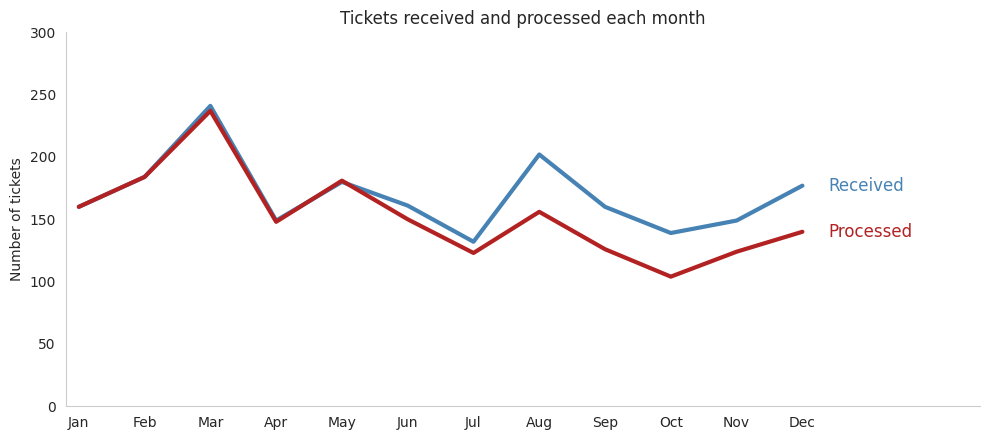

In [23]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
received = [160, 184, 241, 149, 180, 161, 132, 202, 160, 139, 149, 177]
processed = [160, 184, 237, 148, 181, 150, 123, 156, 126, 104, 124, 140]

plt.figure(figsize=(10, 4.5))
plt.plot(months, received, color="steelblue", linewidth=3)
plt.plot(months, processed, color="firebrick", linewidth=3)
plt.title("Tickets received and processed each month")
plt.ylabel("Number of tickets")
plt.ylim(0, 300)
plt.xlim(-0.2, 13.7)

plt.text(11.4, received[-1], "Received", color="steelblue", fontsize=12, va="center")
plt.text(11.4, processed[-1], "Processed", color="firebrick", fontsize=12, va="center")

plt.grid(False)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

I recreated the graph from page 97 because it is easy to understand.